# 02 · Training both models (on IBM LinuxONE)
Same functions as `python -m scamshield.training`, step by step. Nothing here touches the running service.

In [1]:
import sys, os, platform, subprocess
sys.path.insert(0, os.path.expanduser("~/scamshield/src"))
import xgboost  # before torch (see training.py)
import numpy as np, pandas as pd, matplotlib.pyplot as plt
SHARED = os.path.expanduser("~/shared")
RAW = f"{SHARED}/aml"
print(platform.machine(), platform.platform())
print(subprocess.run("grep -E '^Type:' /proc/sysinfo; lscpu | grep -io nnpa | head -1", shell=True,
                     capture_output=True, text=True).stdout)

s390x Linux-6.8.0-147-generic-s390x-with-glibc2.39
Type:                 9175
nnpa



In [2]:
import json, time
from scamshield import training as T
t = time.time()
tx, split, ctx, X = T.prepare(RAW)     # ONE streaming feature engine, the same code the API runs
y = tx.label.values.astype(int)
print(f"{len(tx):,} payments -> {X.shape[1]} features in {time.time()-t:.0f}s on {os.cpu_count()} vCPUs")
{k: round(v, 4) for k, v in sorted(ctx.usd_per_unit.items())}  # exchange rates derived from the data itself

5,077,237 payments -> 31 features in 72s on 3 vCPUs


{'Australian Dollar': 0.7078,
 'Bitcoin': 11881.5035,
 'Brazil Real': 0.1771,
 'Canadian Dollar': 0.758,
 'Euro': 1.1718,
 'Mexican Peso': 0.0473,
 'Ruble': 0.0129,
 'Rupee': 0.0136,
 'Saudi Riyal': 0.2666,
 'Shekel': 0.2961,
 'Swiss Franc': 1.0929,
 'UK Pound': 1.2916,
 'US Dollar': 1.0,
 'Yen': 0.0095,
 'Yuan': 0.1493}

## Risk model: XGBoost on the payment + sender history + receiver (mule) history

In [3]:
booster, meta = T.train_risk_model(X, y, split)
risk = booster.inplace_predict(X)
pd.DataFrame({s: T.ranking_metrics(y[split == s], risk[split == s]) for s in ("val", "test")}).round(4)

,val,test
n,965524.0000,862792.0000
positives,1036.0000,956.0000
base_rate,0.0011,0.0011
pr_auc,0.6152,0.5636
roc_auc,0.9861,0.9844
best_f1,0.6429,0.5869
best_f1_precision,0.8822,0.8478
best_f1_recall,0.5058,0.4487
best_f1_threshold,0.8532,0.8635


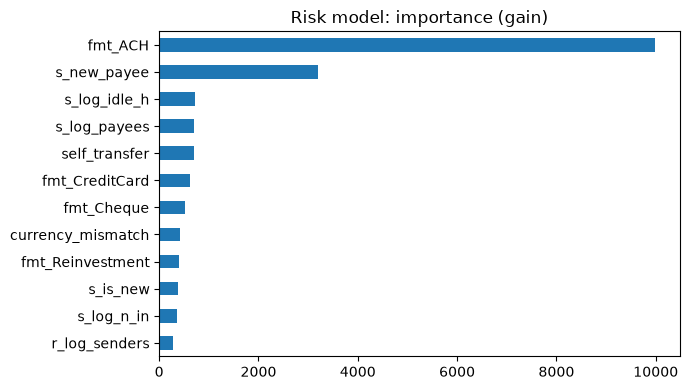

In [4]:
imp = pd.Series(meta["importance_gain"]).sort_values()
imp.tail(12).plot.barh(figsize=(7, 4), title="Risk model: importance (gain)"); plt.tight_layout()

## Customer-side model: PyTorch autoencoder ('is this payment unusual for this customer?')

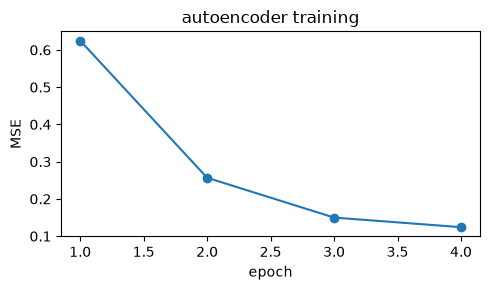

In [5]:
ae, scaler, history = T.train_autoencoder(X, y, split, epochs=4)
plt.figure(figsize=(5, 3)); plt.plot(range(1, len(history) + 1), history, "o-")
plt.xlabel("epoch"); plt.ylabel("MSE"); plt.title("autoencoder training"); plt.tight_layout()

## Run it on the Telum II on-chip AI accelerator
`torch_nnpa` registers an `nnpa` device: moving the model there is one line.

In [6]:
import torch, torch_nnpa, copy
print("NNPA available:", torch_nnpa.NNPAModule.is_available(), "| Telum II:", torch_nnpa.NNPAModule.is_telum2_available())
dev = torch_nnpa.device()
ae_nnpa = copy.deepcopy(ae).to(dev).eval()
Z = torch.from_numpy(scaler.transform(X[split == "test"][:4096][:, T.AE_IDX]))
with torch.no_grad():
    print("max |cpu - nnpa| =", float((ae(Z) - ae_nnpa(Z.to(dev)).cpu()).abs().max()))
for name, fn in [("cpu", lambda: ae(Z)), ("nnpa", lambda: ae_nnpa(Z.to(dev)).cpu())]:
    with torch.no_grad():
        for _ in range(20):
            fn()
        t = time.perf_counter()
        for _ in range(200):
            fn()
        dt = (time.perf_counter() - t) / 200
    print(f"{name}: {dt*1e6:.0f} us per 4096-payment batch -> {4096/dt:,.0f} payments/s")

NNPA available: True | Telum II: True
max |cpu - nnpa| = 0.06636717915534973


cpu: 787 us per 4096-payment batch -> 5,206,615 payments/s
nnpa: 531 us per 4096-payment batch -> 7,708,865 payments/s


## Decisions on the unseen test days (from the production training run)

In [7]:
m = json.load(open(f"{SHARED}/models/metrics.json"))
print(json.dumps(m["thresholds"], indent=1))
d = m["decisions"]["test"]
pd.Series({"allow": d["mix"]["ALLOW"], "warn": d["mix"]["WARN"], "hold": d["mix"]["HOLD"],
           "hold precision": d["hold_precision"], "laundering held": d["laundering_recall_hold"],
           "laundering warned or held": d["laundering_recall_warn_or_hold"],
           "USD held (M)": d["laundered_usd_held"] / 1e6, "USD laundered (M)": d["laundered_usd_total"] / 1e6,
           "schemes disrupted": d["schemes_disrupted_total"]})

{
 "anomaly_threshold": 0.9007520822882663,
 "warn_threshold": 0.1281326860189438,
 "hold_threshold": 0.7586358785629272,
 "hold_min_precision_val": 0.6,
 "hold_cap": 0.002,
 "warn_budget": 0.0125
}


allow                           0.98263
warn                            0.01628
hold                            0.00108
hold precision                  0.53312
laundering held                0.521967
laundering warned or held      0.820084
USD held (M)                 269.326102
USD laundered (M)            424.326853
schemes disrupted               150/174
dtype: object

In [8]:
pd.Series(d["schemes_disrupted"]).rename("schemes with a payment held")

BIPARTITE         12/16
CYCLE             19/22
FAN-IN            16/18
FAN-OUT           18/20
GATHER-SCATTER    32/37
RANDOM            14/17
SCATTER-GATHER    19/22
STACK             20/22
Name: schemes with a payment held, dtype: str